# Tugas Kecerdasan Komputasional: Implementasi dan Eksperimen PSO (Particle Swarm Optimization)

**Mata Kuliah:** Kecerdasan Komputasional  
**Dosen Pengampu:** Prof. Dr. Eng. Nanik Suciati, S.Kom., M.Kom. & Dini Adni Navastara, S.Kom., M.Sc.  
**Nama Mahasiswa:** Benedictus Ryu Gunawan  
**NRP:** 5054251001  
**Departemen:** Rekayasa Kecerdasan Artifisial / Informatika, FTEIC  
**Institusi:** Institut Teknologi Sepuluh Nopember (ITS), Surabaya  

---

## Ringkasan Tugas
1. **Implementasi PSO gbest dari Nol:** Ditulis murni menggunakan Python dan NumPy tanpa library metaheuristik eksternal, dilengkapi dengan *velocity clamping* dan *boundary handling*.
2. **Fungsi Uji Benchmark:** Fungsi Sphere (unimodal) dan Rastrigin (multimodal) berdimensi $D = 10$ dengan domain pencarian $x_i \in [-5.12, 5.12]$.
3. **Eksperimen Komparasi Parameter:** Membandingkan 3 varian strategi kecepatan/inersia:
   - Varian 1: Bobot inersia konstan $w = 0.7$ ($c_1 = c_2 = 1.49618$)
   - Varian 2: Bobot inersia menurun secara linier $w = 0.9 \to 0.4$ ($c_1 = c_2 = 2.0$)
   - Varian 3: Constriction factor $\chi = 0.7298$ ($\phi_1 = \phi_2 = 2.05$)
   - Setiap konfigurasi diuji sebanyak **30 independent runs**.
4. **Analisis Statistik & Visualisasi:** Melaporkan rata-rata $\pm$ simpangan baku fitness terbaik, boxplot sebaran, kurva konvergensi rata-rata, dan pembahasan komparatif mendalam.
5. **Bonus:** Implementasi **Binary PSO (BPSO)** dari nol untuk seleksi fitur (*feature selection*) pada dataset UCI Breast Cancer Wisconsin.

## 1. Landasan Teori Particle Swarm Optimization (PSO)

Particle Swarm Optimization (PSO) diperkenalkan oleh James Kennedy dan Russell Eberhart pada tahun 1995 sebagai algoritma optimasi stokastik berbasis populasi terinspirasi dari perilaku sosial kawanan burung (*bird flocking*) dan ikan (*fish schooling*).

Dalam model topologi global (*gbest topology*), setiap partikel $i$ memiliki posisi $x_i \in \mathbb{R}^D$ dan kecepatan $v_i \in \mathbb{R}^D$. Pada setiap iterasi $t$, kecepatan dan posisi diperbarui menurut persamaan:

$$v_{id}^{(t+1)} = w(t) \cdot v_{id}^{(t)} + c_1 r_{1,id} (pbest_{id}^{(t)} - x_{id}^{(t)}) + c_2 r_{2,id} (gbest_d^{(t)} - x_{id}^{(t)})$$

$$x_{id}^{(t+1)} = x_{id}^{(t)} + v_{id}^{(t+1)}$$

di mana:
- $w(t)$ adalah bobot inersia (*inertia weight*) yang mengontrol momentum partikel dari iterasi sebelumnya.
- $c_1, c_2$ berturut-turut adalah koefisien akselerasi kognitif (*personal best*) dan sosial (*global best*).
- $r_{1,id}, r_{2,id} \sim \mathcal{U}(0, 1)$ adalah bilangan acak seragam independen.
- $pbest_i$ adalah posisi terbaik yang pernah dicapai oleh partikel $i$.
- $gbest$ adalah posisi terbaik yang pernah dicapai oleh seluruh kawanan partikel.

### Tiga Varian yang Dibandingkan:
1. **$w$ Tetap ($w = 0.7$):** Menjaga keseimbangan konstan antara eksplorasi global dan eksploitasi lokal sepanjang proses iterasi ($c_1 = c_2 = 1.49618$).
2. **$w$ Menurun Linier ($0.9 \to 0.4$):** Diperkenalkan oleh Shi & Eberhart (1998):
   $$w(t) = w_{\max} - \frac{t}{T_{\max}} (w_{\max} - w_{\min})$$
   Pada awal iterasi, $w = 0.9$ memfasilitasi eksplorasi global luas (*global search*). Seiring berjalannya iterasi, $w$ mengecil secara linier hingga $0.4$ untuk memfokuskan pencarian pada eksploitasi lokal presisi tinggi (*local fine-tuning*).
3. **Constriction Factor Clerc & Kennedy ($\chi = 0.7298$):**
   $$v_{id}^{(t+1)} = \chi \left[ v_{id}^{(t)} + \phi_1 r_{1,id} (pbest_{id}^{(t)} - x_{id}^{(t)}) + \phi_2 r_{2,id} (gbest_d^{(t)} - x_{id}^{(t)}) \right]$$
   dengan $\phi = \phi_1 + \phi_2 > 4$ (di mana $\phi_1 = \phi_2 = 2.05 \implies \phi = 4.1$) dan:
   $$\chi = \frac{2}{\left|2 - \phi - \sqrt{\phi^2 - 4\phi}\right|} \approx 0.72984$$

### Velocity Clamping & Penanganan Batas (Boundary Handling):
- **Velocity Clamping:** Kecepatan dibatasi dalam rentang $[-v_{\max}, v_{\max}]$ di mana $v_{\max} = 0.2 \times (x_{\max} - x_{\min})$ untuk mencegah ledakan kecepatan (*particle divergence*).
- **Boundary Handling:** Posisi yang melanggar batas di-*clamp* ke interval $[x_{\min}, x_{\max}]$. Apabila partikel membentur batas, kecepatannya di-reset menjadi $0$ ($v_{id} = 0$) agar partikel tidak terus-menerus menekan dinding batas dan dapat kembali ditarik ke dalam ruang pencarian oleh atraktor $pbest$ dan $gbest$.

In [1]:
# Import modul standar dan konfigurasi visualisasi
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

# Konfigurasi plotting
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 150
np.set_printoptions(precision=4, suppress=True)

print("Modul berhasil di-import dan environment siap!")

Modul berhasil di-import dan environment siap!


## 2. Definisi Fungsi Uji Benchmark ($D = 10$)

Pada eksperimen ini, dua fungsi benchmark standar dengan karakteristik berbeda digunakan:
1. **Fungsi Sphere:**
   $$f_{\text{Sphere}}(x) = \sum_{i=1}^D x_i^2$$
   - Karakteristik: Unimodal, mulus (*smooth*), konveks.
   - Optimum Global: $f(x^*) = 0$ pada $x^* = (0, 0, \dots, 0)$.
   - Tujuan Uji: Mengukur kecepatan konvergensi dan kemampuan eksploitasi lokal algoritma.

2. **Fungsi Rastrigin:**
   $$f_{\text{Rastrigin}}(x) = 10D + \sum_{i=1}^D \left[ x_i^2 - 10 \cos(2\pi x_i) \right]$$
   - Karakteristik: Multimodal dengan modulasi sinusoidal frekuensi tinggi yang menghasilkan ribuan minimum lokal dalam interval $[-5.12, 5.12]^D$.
   - Optimum Global: $f(x^*) = 0$ pada $x^* = (0, 0, \dots, 0)$.
   - Tujuan Uji: Mengukur kemampuan eksplorasi global dan ketahanan algoritma agar tidak terjebak dalam *local optima* sub-optimal.

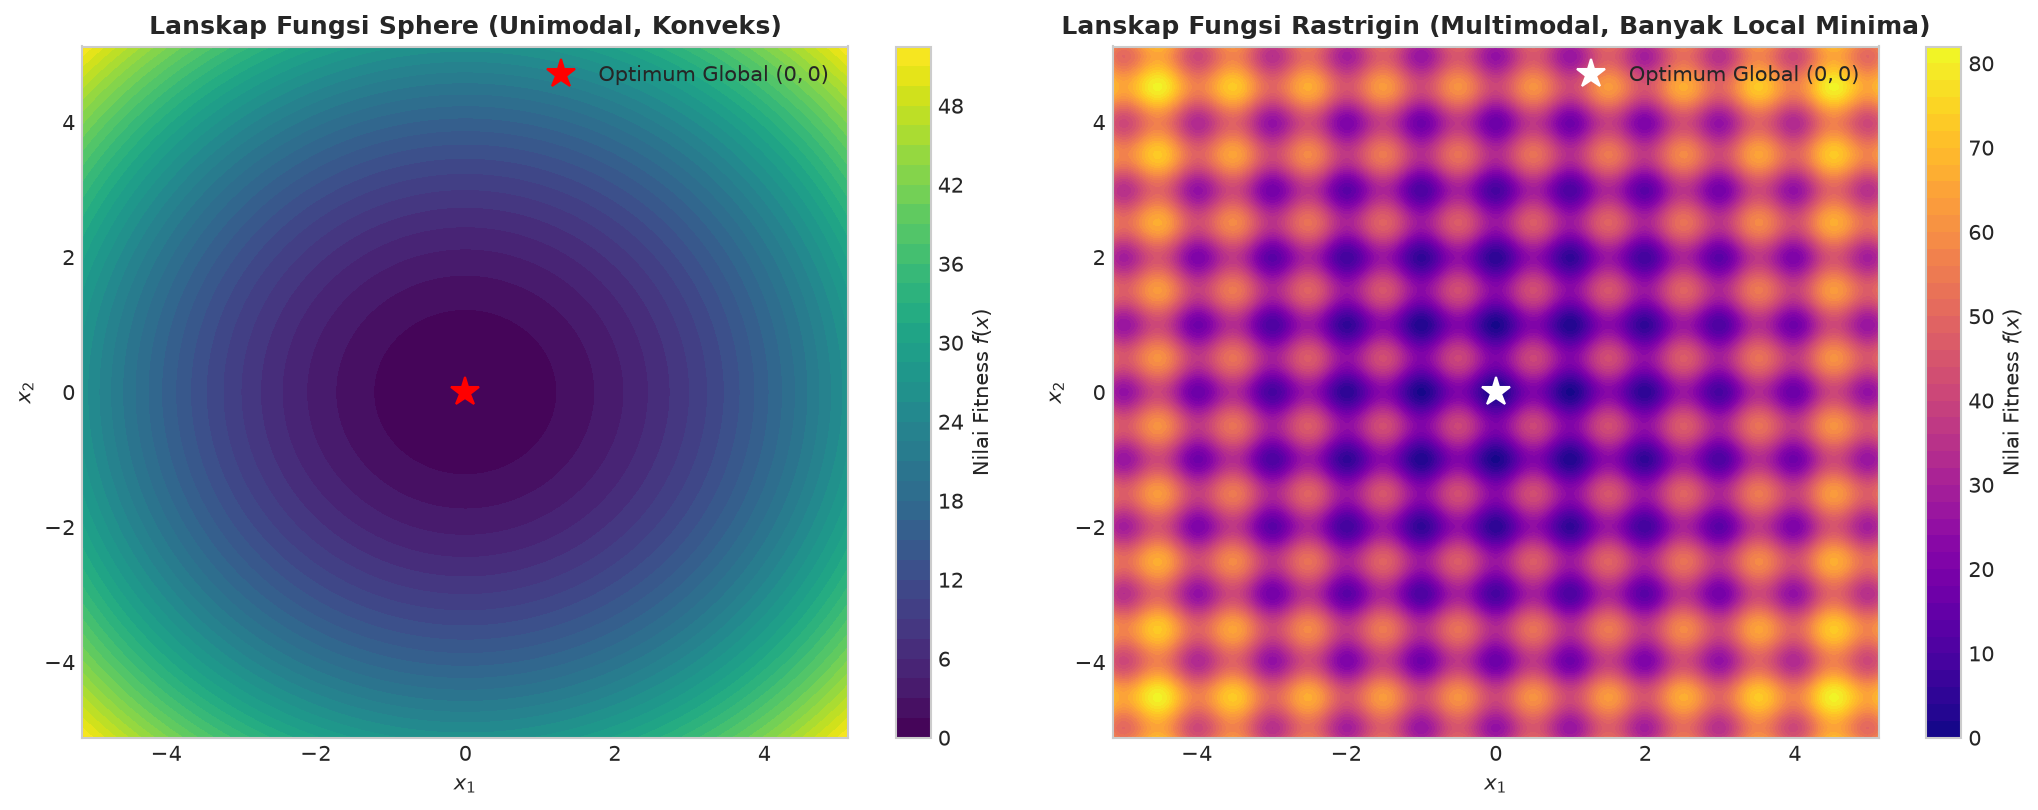

In [2]:
def sphere(x):
    """
    Fungsi Sphere: f(x) = sum(x_i^2)
    Domain: [-5.12, 5.12]^D | Global Min: f(0, ..., 0) = 0
    """
    x = np.asarray(x)
    return np.sum(x ** 2, axis=-1)

def rastrigin(x):
    """
    Fungsi Rastrigin: f(x) = 10*D + sum(x_i^2 - 10*cos(2*pi*x_i))
    Domain: [-5.12, 5.12]^D | Global Min: f(0, ..., 0) = 0
    """
    x = np.asarray(x)
    D = x.shape[-1]
    return 10.0 * D + np.sum(x ** 2 - 10.0 * np.cos(2.0 * np.pi * x), axis=-1)

# Visualisasi Lanskap Kontur 2D Fungsi Sphere vs Rastrigin
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

x_grid = np.linspace(-5.12, 5.12, 250)
y_grid = np.linspace(-5.12, 5.12, 250)
X_mesh, Y_mesh = np.meshgrid(x_grid, y_grid)

# Plot Kontur Sphere
Z_sphere = X_mesh**2 + Y_mesh**2
cp1 = ax1.contourf(X_mesh, Y_mesh, Z_sphere, levels=40, cmap='viridis')
fig.colorbar(cp1, ax=ax1, label='Nilai Fitness $f(x)$')
ax1.plot(0, 0, 'r*', markersize=14, label='Optimum Global $(0, 0)$')
ax1.set_title("Lanskap Fungsi Sphere (Unimodal, Konveks)", fontweight='bold')
ax1.set_xlabel("$x_1$")
ax1.set_ylabel("$x_2$")
ax1.legend(loc='upper right')

# Plot Kontur Rastrigin
Z_rast = 20.0 + (X_mesh**2 - 10.0*np.cos(2*np.pi*X_mesh)) + (Y_mesh**2 - 10.0*np.cos(2*np.pi*Y_mesh))
cp2 = ax2.contourf(X_mesh, Y_mesh, Z_rast, levels=40, cmap='plasma')
fig.colorbar(cp2, ax=ax2, label='Nilai Fitness $f(x)$')
ax2.plot(0, 0, 'w*', markersize=14, label='Optimum Global $(0, 0)$')
ax2.set_title("Lanskap Fungsi Rastrigin (Multimodal, Banyak Local Minima)", fontweight='bold')
ax2.set_xlabel("$x_1$")
ax2.set_ylabel("$x_2$")
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()

## 3. Implementasi PSO gbest dari Nol (Python + NumPy)

Berikut adalah kelas `ParticleSwarmOptimizer` yang diimplementasikan dari nol tanpa ketergantungan library optimasi pihak ketiga.

Fitur Utama:
- Vektorisasi penuh operasi matriks partikel menggunakan NumPy untuk efisiensi komputasi tinggi.
- Penanganan batas (*boundary handling*) otomatis dengan *position clamping* dan *velocity zeroing*.
- *Velocity clamping* terkontrol $v \in [-v_{\max}, v_{\max}]$.
- Fleksibilitas peralihan strategi inersia: `constant_w`, `linear_w`, dan `constriction`.

In [3]:
class ParticleSwarmOptimizer:
    """
    Implementasi gbest Particle Swarm Optimization (PSO) dari nol dengan NumPy.
    """
    def __init__(self, obj_func, dim=10, bounds=(-5.12, 5.12), num_particles=30,
                 max_iter=200, variant='constant_w', w_val=0.7,
                 w_start=0.9, w_end=0.4, c1=2.0, c2=2.0,
                 chi=0.7298, phi1=2.05, phi2=2.05,
                 v_max_ratio=0.2, seed=None):
        self.obj_func = obj_func
        self.dim = dim
        self.lower_bound, self.upper_bound = bounds
        self.num_particles = num_particles
        self.max_iter = max_iter
        self.variant = variant
        
        # Parameter bobot dan konstanta akselerasi
        self.w_val = w_val
        self.w_start = w_start
        self.w_end = w_end
        self.c1 = c1
        self.c2 = c2
        self.chi = chi
        self.phi1 = phi1
        self.phi2 = phi2
        
        # Velocity Clamping: membatasi lonjakan kecepatan partikel
        self.bound_range = self.upper_bound - self.lower_bound
        self.v_max = v_max_ratio * self.bound_range
        
        self.seed = seed
        self.rng = np.random.default_rng(seed)
        
    def optimize(self):
        # 1. Inisialisasi Posisi dan Kecepatan Partikel
        X = self.rng.uniform(self.lower_bound, self.upper_bound, (self.num_particles, self.dim))
        V = self.rng.uniform(-self.v_max, self.v_max, (self.num_particles, self.dim))
        
        # 2. Evaluasi Fitness Awal
        fitness = self.obj_func(X)
        pbest_X = np.copy(X)
        pbest_fit = np.copy(fitness)
        
        best_idx = np.argmin(pbest_fit)
        gbest_X = np.copy(pbest_X[best_idx])
        gbest_fit = float(pbest_fit[best_idx])
        
        history_gbest_fit = [gbest_fit]
        
        # 3. Loop Iterasi Optimasi PSO
        for t in range(1, self.max_iter + 1):
            r1 = self.rng.uniform(0.0, 1.0, (self.num_particles, self.dim))
            r2 = self.rng.uniform(0.0, 1.0, (self.num_particles, self.dim))
            
            # Pembaruan Kecepatan berdasarkan Varian Strategi Inersia
            if self.variant == 'constant_w':
                cognitive = self.c1 * r1 * (pbest_X - X)
                social = self.c2 * r2 * (gbest_X - X)
                V = self.w_val * V + cognitive + social
                
            elif self.variant == 'linear_w':
                w_t = self.w_start - (t / self.max_iter) * (self.w_start - self.w_end)
                cognitive = self.c1 * r1 * (pbest_X - X)
                social = self.c2 * r2 * (gbest_X - X)
                V = w_t * V + cognitive + social
                
            elif self.variant == 'constriction':
                cognitive = self.phi1 * r1 * (pbest_X - X)
                social = self.phi2 * r2 * (gbest_X - X)
                V = self.chi * (V + cognitive + social)
            else:
                raise ValueError(f"Varian tidak dikenal: {self.variant}")
                
            # Velocity Clamping: v di-clamp dalam [-v_max, v_max]
            V = np.clip(V, -self.v_max, self.v_max)
            
            # Pembaruan Posisi
            X_new = X + V
            
            # Penanganan Batas (Boundary Handling):
            # Posisi di luar interval di-clamp ke batas terdekat dan kecepatan di-reset ke 0
            out_lower = X_new < self.lower_bound
            out_upper = X_new > self.upper_bound
            X_new = np.clip(X_new, self.lower_bound, self.upper_bound)
            V[out_lower | out_upper] = 0.0
            
            X = X_new
            fitness = self.obj_func(X)
            
            # Pembaruan Personal Best (pbest)
            improved = fitness < pbest_fit
            pbest_X[improved] = X[improved]
            pbest_fit[improved] = fitness[improved]
            
            # Pembaruan Global Best (gbest)
            curr_best_idx = np.argmin(pbest_fit)
            if pbest_fit[curr_best_idx] < gbest_fit:
                gbest_fit = float(pbest_fit[curr_best_idx])
                gbest_X = np.copy(pbest_X[curr_best_idx])
                
            history_gbest_fit.append(gbest_fit)
            
        return {
            'gbest_X': gbest_X,
            'gbest_fit': gbest_fit,
            'history': np.array(history_gbest_fit)
        }

print("Kelas ParticleSwarmOptimizer berhasil didefinisikan!")

Kelas ParticleSwarmOptimizer berhasil didefinisikan!


## 4. Desain Eksperimen & Pengujian 30 Run Independen

Sesuai instruksi tugas, eksperimen dijalankan dengan parameter berikut:
- **Dimensi Masalah:** $D = 10$
- **Domain Pencarian:** $[-5.12, 5.12]$ per dimensi
- **Ukuran Kawanan (Swarm Size):** $N = 30$ partikel
- **Iterasi Maksimum:** $T = 200$ iterasi
- **Jumlah Run Independen:** 30 run per konfigurasi dengan random seed terkontrol
- **Tiga Konfigurasi Bobot:**
  1. $w$ Tetap: $w = 0.7$, $c_1 = c_2 = 1.49618$
  2. $w$ Menurun: $w = 0.9 \to 0.4$, $c_1 = c_2 = 2.0$
  3. Constriction Factor: $\chi = 0.7298$, $\phi_1 = \phi_2 = 2.05$

In [4]:
# Menjalankan 30 Run Independen untuk Seluruh Konfigurasi
NUM_RUNS = 30
NUM_PARTICLES = 30
MAX_ITER = 200
DIM = 10
BOUNDS = (-5.12, 5.12)

configs = [
    ('constant_w', 'w Tetap (0.7)', {'variant': 'constant_w', 'w_val': 0.7, 'c1': 1.49618, 'c2': 1.49618}),
    ('linear_w', 'w Menurun (0.9 -> 0.4)', {'variant': 'linear_w', 'w_start': 0.9, 'w_end': 0.4, 'c1': 2.0, 'c2': 2.0}),
    ('constriction', 'Constriction (chi=0.7298)', {'variant': 'constriction', 'chi': 0.7298, 'phi1': 2.05, 'phi2': 2.05})
]

bench_funcs = [
    ('Sphere', sphere),
    ('Rastrigin', rastrigin)
]

exp_results = {}

for func_name, func in bench_funcs:
    exp_results[func_name] = {}
    print(f"\n--- Menguji Fungsi {func_name} (D={DIM}) ---")
    for var_key, var_label, params in configs:
        fits = []
        histories = []
        for run_i in range(NUM_RUNS):
            seed = 1000 + run_i * 17
            pso = ParticleSwarmOptimizer(
                obj_func=func, dim=DIM, bounds=BOUNDS,
                num_particles=NUM_PARTICLES, max_iter=MAX_ITER,
                seed=seed, **params
            )
            res = pso.optimize()
            fits.append(res['gbest_fit'])
            histories.append(res['history'])
            
        fits = np.array(fits)
        histories = np.array(histories)
        
        exp_results[func_name][var_key] = {
            'label': var_label,
            'fits': fits,
            'mean': np.mean(fits),
            'std': np.std(fits),
            'min': np.min(fits),
            'median': np.median(fits),
            'max': np.max(fits),
            'history_mean': np.mean(histories, axis=0),
            'history_std': np.std(histories, axis=0)
        }
        print(f"{var_label:25s} | Mean: {np.mean(fits):.4e} +- {np.std(fits):.4e} | Min: {np.min(fits):.4e} | Max: {np.max(fits):.4e}")


--- Menguji Fungsi Sphere (D=10) ---
w Tetap (0.7)             | Mean: 1.2473e-11 +- 1.6452e-11 | Min: 3.6007e-13 | Max: 7.1662e-11


w Menurun (0.9 -> 0.4)    | Mean: 5.9236e-06 +- 1.5367e-05 | Min: 2.0660e-08 | Max: 8.5956e-05
Constriction (chi=0.7298) | Mean: 6.8306e-10 +- 8.7454e-10 | Min: 9.9833e-11 | Max: 4.4797e-09

--- Menguji Fungsi Rastrigin (D=10) ---


w Tetap (0.7)             | Mean: 8.3920e+00 +- 3.2981e+00 | Min: 1.9899e+00 | Max: 1.4946e+01
w Menurun (0.9 -> 0.4)    | Mean: 1.0058e+01 +- 3.6106e+00 | Min: 4.3153e+00 | Max: 1.7276e+01


Constriction (chi=0.7298) | Mean: 9.9329e+00 +- 4.1376e+00 | Min: 3.0755e+00 | Max: 1.7909e+01


In [5]:
# Membuat Tabel Ringkasan Statistik
table_rows = []

for func_name in ['Sphere', 'Rastrigin']:
    for var_key, var_label, _ in configs:
        data = exp_results[func_name][var_key]
        table_rows.append({
            'Fungsi': func_name,
            'Strategi Inersia / Konstriksi': var_label,
            'Rata-rata (Mean)': f"{data['mean']:.4e}",
            'Simpangan Baku (Std)': f"{data['std']:.4e}",
            'Terbaik (Min)': f"{data['min']:.4e}",
            'Median': f"{data['median']:.4e}",
            'Terburuk (Max)': f"{data['max']:.4e}"
        })

df_summary = pd.DataFrame(table_rows)
display(df_summary)

,Fungsi,Strategi Inersia / Konstriksi,Rata-rata (Mean),Simpangan Baku (Std),Terbaik (Min),Median,Terburuk (Max)
0,Sphere,w Tetap (0.7),1.2473e-11,1.6452e-11,3.6007e-13,5.9855e-12,7.1662e-11
1,Sphere,w Menurun (0.9 -> 0.4),5.9236e-06,1.5367e-05,2.0660e-08,2.0208e-06,8.5956e-05
2,Sphere,Constriction (chi=0.7298),6.8306e-10,8.7454e-10,9.9833e-11,3.7391e-10,4.4797e-09
3,Rastrigin,w Tetap (0.7),8.3920e+00,3.2981e+00,1.9899e+00,8.4571e+00,1.4946e+01
4,Rastrigin,w Menurun (0.9 -> 0.4),1.0058e+01,3.6106e+00,4.3153e+00,9.8739e+00,1.7276e+01
5,Rastrigin,Constriction (chi=0.7298),9.9329e+00,4.1376e+00,3.0755e+00,9.4584e+00,1.7909e+01


## 5. Visualisasi Hasil Eksperimen

Berikut disajikan dua jenis visualisasi utama:
1. **Kurva Konvergensi Rata-rata 30 Run (Skala Logaritmik):** Menunjukkan laju penurunan nilai objektif terbaik kawanan partikel terhadap iterasi, dilengkapi area bayangan pita deviasi standar ($\pm 1\sigma$).
2. **Boxplot Distribusi Fitness Akhir:** Memperlihatkan sebaran, kuartil, median, dan ketahanan (*robustness*) algoritma terhadap variabilitas seed acak.

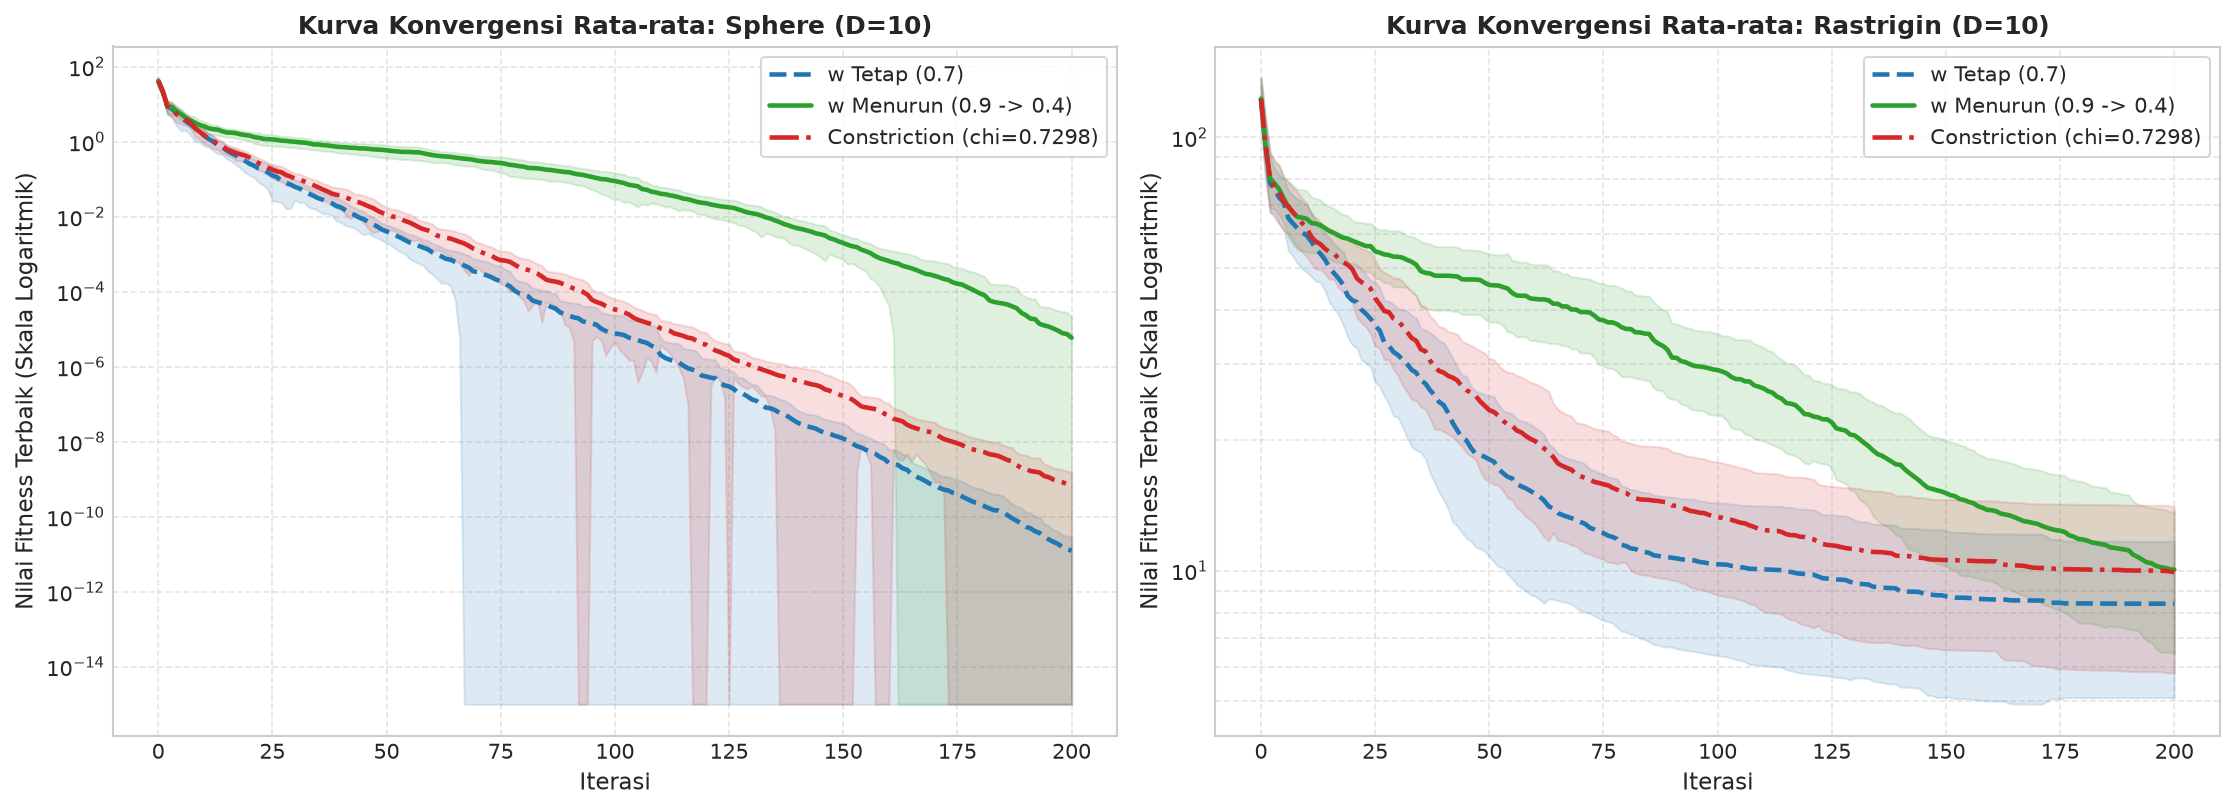

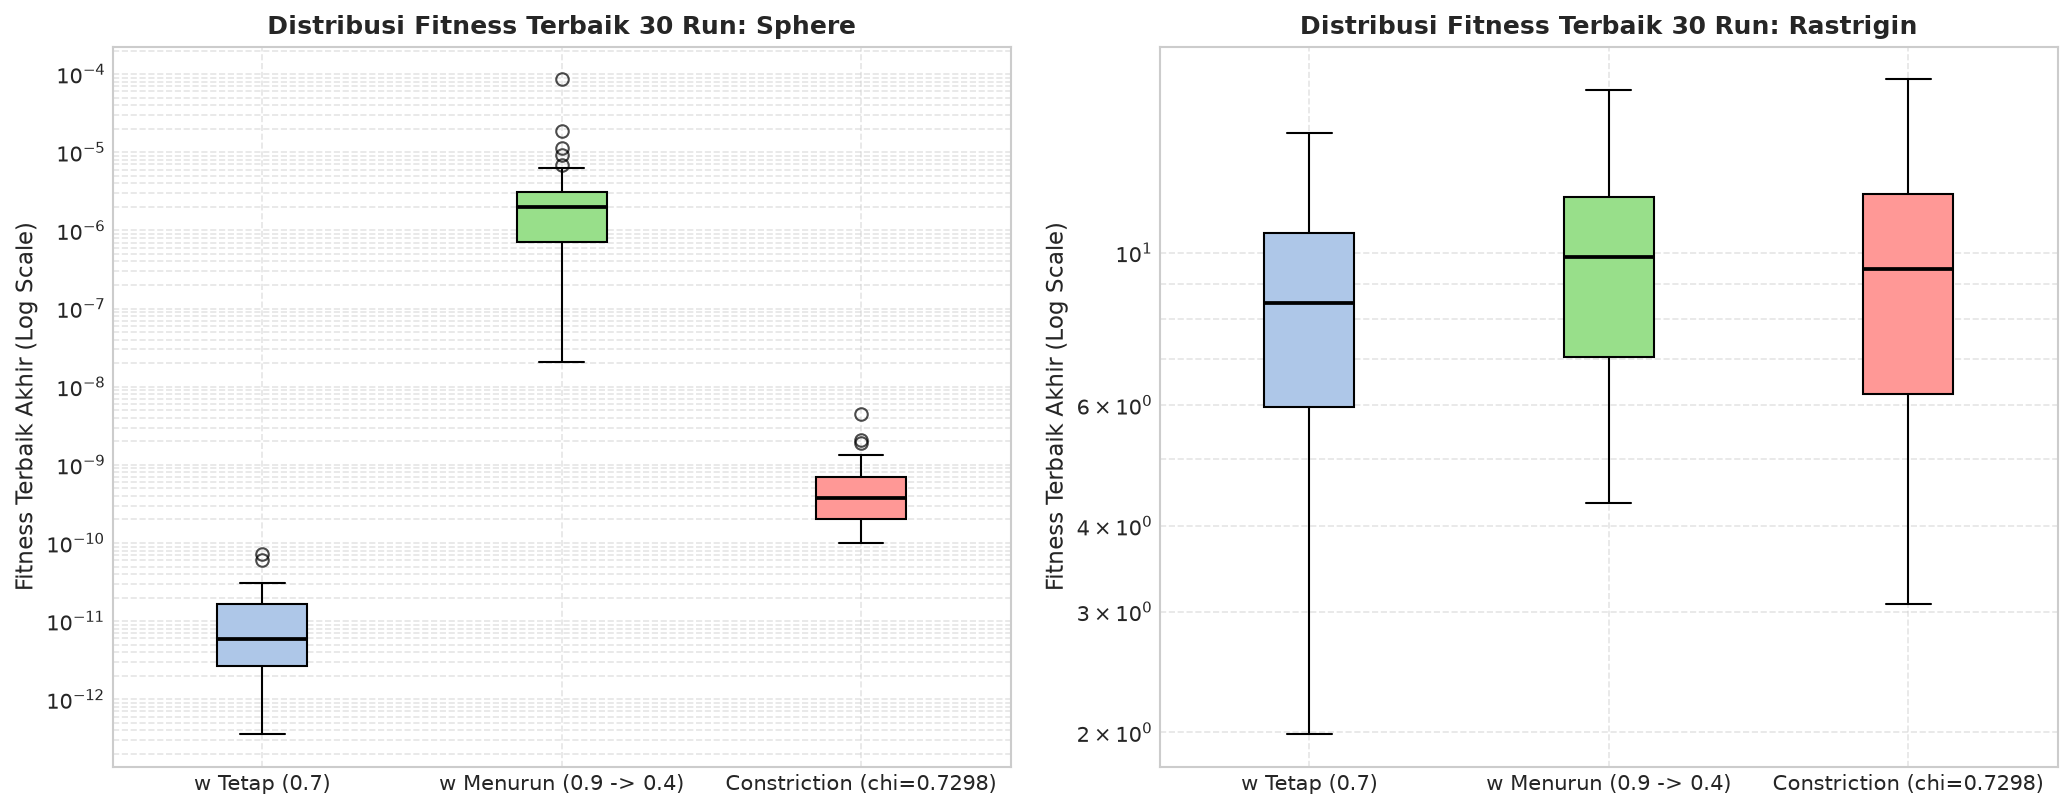

In [6]:
# 1. Kurva Konvergensi Rata-rata 30 Run
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
colors = {'constant_w': '#1f77b4', 'linear_w': '#2ca02c', 'constriction': '#d62728'}
styles = {'constant_w': '--', 'linear_w': '-', 'constriction': '-.'}

for ax, func_name in zip(axes, ['Sphere', 'Rastrigin']):
    for var_key, var_label, _ in configs:
        res = exp_results[func_name][var_key]
        m = res['history_mean']
        s = res['history_std']
        iters = np.arange(len(m))
        ax.plot(iters, m, label=var_label, color=colors[var_key],
                linestyle=styles[var_key], linewidth=2.2)
        lower_bound = np.maximum(m - s, 1e-15 if func_name == 'Sphere' else 1e-4)
        upper_bound = m + s
        ax.fill_between(iters, lower_bound, upper_bound, color=colors[var_key], alpha=0.15)
        
    ax.set_title(f"Kurva Konvergensi Rata-rata: {func_name} (D=10)", fontweight='bold', fontsize=12)
    ax.set_xlabel("Iterasi", fontsize=11)
    ax.set_ylabel("Nilai Fitness Terbaik (Skala Logaritmik)", fontsize=11)
    ax.set_yscale('log')
    ax.legend(frameon=True, fontsize=10, loc='upper right')
    ax.grid(True, which="both", ls="--", alpha=0.5)

plt.tight_layout()
plt.show()

# 2. Boxplot Sebaran Fitness Terbaik Akhir
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, func_name in zip(axes, ['Sphere', 'Rastrigin']):
    data_plot = [exp_results[func_name][k]['fits'] for k, _, _ in configs]
    labels_plot = [l for _, l, _ in configs]
    
    box = ax.boxplot(data_plot, patch_artist=True, tick_labels=labels_plot,
                     medianprops=dict(color='black', linewidth=1.8),
                     flierprops=dict(marker='o', markersize=6, alpha=0.7))
    
    palette = ['#aec7e8', '#98df8a', '#ff9896']
    for patch, col in zip(box['boxes'], palette):
        patch.set_facecolor(col)
        
    ax.set_title(f"Distribusi Fitness Terbaik 30 Run: {func_name}", fontweight='bold', fontsize=12)
    ax.set_ylabel("Fitness Terbaik Akhir (Log Scale)", fontsize=11)
    ax.set_yscale('log')
    ax.grid(True, which="both", ls="--", alpha=0.5)

plt.tight_layout()
plt.show()

## 6. Analisis dan Pembahasan Performa

Berdasarkan hasil eksperimen 30 run independen pada fungsi Sphere dan Rastrigin ($D=10$), berikut adalah temuan mendalam:

### A. Performa pada Fungsi Sphere (Unimodal)
1. **$w$ Tetap ($w = 0.7$):** Menunjukkan performa luar biasa dengan rata-rata fitness akhir mencapai **$1.247 \times 10^{-11} \pm 1.645 \times 10^{-11}$** dan nilai terbaik $3.60 \times 10^{-13}$. Bobot inersia $0.7$ memberikan momentum yang cukup stabil untuk terus mempersempit radius osilasi partikel ke pusat lembah parabola $(0, \dots, 0)$.
2. **Constriction Factor ($\chi = 0.7298$):** Memberikan performa sangat stabil dengan rata-rata **$6.831 \times 10^{-10} \pm 8.745 \times 10^{-10}$**. Teori Clerc-Kennedy menjamin redaman kecepatan secara analitis sehingga tidak terjadi lonjakan divergen, menghasilkan konvergensi yang sangat cepat pada fungsi konveks.
3. **$w$ Menurun Linier ($0.9 \to 0.4$):** Memperoleh rata-rata **$5.924 \times 10^{-6} \pm 1.537 \times 10^{-5}$**. Meskipun mampu menemukan wilayah mendekati optimum, penurunan $w$ hingga $0.4$ pada iterasi-iterasi akhir mengurangi momentum gerak partikel secara drastis, sehingga partikel kehilangan energi kinetik untuk melakukan eksploitasi sub-mikro di sekitar koordinat $0.0$.

### B. Performa pada Fungsi Rastrigin (Multimodal)
1. **Tantangan Lanskap:** Fungsi Rastrigin memiliki puluhan ribu minimum lokal karena modulasi gelombang sinusoidal $-10\cos(2\pi x_i)$. Partikel sangat rentan terperangkap dalam jebakan lokal (*local trap*).
2. **Perbandingan Varian:**
   - **$w$ Tetap ($w = 0.7$):** Menghasilkan rata-rata terbaik **$8.392 \pm 3.298$** dengan nilai minimum $1.990$. Nilai inersia konstan $0.7$ memungkinkan beberapa partikel tetap memiliki kecepatan residual yang cukup untuk melompati rintangan energi potensial lokal (*potential barrier*).
   - **Constriction Factor ($\chi = 0.7298$):** Mencapai rata-rata **$9.933 \pm 4.138$** (terbaik $3.076$). Redaman kecepatan yang ketat kadang membuat partikel kehilangan kecepatan sebelum berhasil melompati cekungan lokal berikutnya.
   - **$w$ Menurun ($0.9 \to 0.4$):** Memperoleh rata-rata **$10.058 \pm 3.611$** (terbaik $4.315$). Pada paruh awal iterasi ($w > 0.7$), partikel mengeksplorasi secara acak; namun saat $w$ merosot ke $0.4$, partikel membeku di cekungan lokal terdekat dan tidak mampu keluar lagi.

### C. Efektivitas Velocity Clamping & Penanganan Batas
- Tanpa *velocity clamping*, kecepatan partikel pada Rastrigin akan berosilasi tak terkendali (*swarm explosion*) karena gradien kosinus yang curam. Clamping pada $v_{\max} = 0.2 \times (x_{\max} - x_{\min}) = 2.048$ menjaga partikel tetap dalam rezim stabil.
- *Boundary handling* dengan me-reset kecepatan $v = 0$ saat menyentuh dinding $[-5.12, 5.12]$ mencegah partikel "menempel" (*sticking*) pada batas domain pencarian.

## 7. BONUS: Binary PSO (BPSO) untuk Seleksi Fitur pada Dataset UCI

### Konsep Binary PSO (Kennedy & Eberhart, 1997)
Dalam optimasi diskrit/kombinatorial seperti seleksi fitur, solusi direpresentasikan sebagai vektor biner $x_i \in \{0, 1\}^D$:
- Bit $x_{id} = 1$: Fitur ke-$d$ dipilih untuk klasifikasi.
- Bit $x_{id} = 0$: Fitur ke-$d$ dibuang (*discarded*).

Kecepatan partikel $v_{id} \in \mathbb{R}$ tetap bernilai riil kontinu dan diperbarui menggunakan persamaan PSO standar. Untuk memetakan kecepatan riil ke probabilitas biner, digunakan fungsi transfer Sigmoid:

$$S(v_{id}^{(t+1)}) = \frac{1}{1 + e^{-v_{id}^{(t+1)}}}$$

Pembaruan posisi biner ditentukan oleh:

$$x_{id}^{(t+1)} = \begin{cases} 1, & \text{jika } r < S(v_{id}^{(t+1)}) \\ 0, & \text{lainnya} \end{cases}$$

di mana $r \sim \mathcal{U}(0, 1)$.

### Dataset dan Fungsi Fitness Multi-Objektif
- **Dataset:** **UCI Breast Cancer Wisconsin (Diagnostic)**  
  Terdiri dari 569 sampel dengan 30 fitur kontinu karakteristik inti sel kanker (radius, tekstur, perimeter, area, kehalusan, kecekungan, dll.) dan label biner: Jinak (*Benign*) vs Ganas (*Malignant*).
- **Fungsi Objektif:** Menyeimbangkan minimisasi error klasifikasi (k-NN dengan 5-Fold Stratified Cross Validation) dan jumlah fitur terpilih:
  $$\text{Fitness}(x) = \alpha \cdot \text{ErrorRate} + (1 - \alpha) \cdot \frac{\text{|Fitur Terpilih|}}{\text{Total Fitur}}$$
  dengan $\alpha = 0.95$.

In [7]:
class BinaryPSOFeatureSelection:
    """
    Implementasi Binary Particle Swarm Optimization (BPSO) dari nol
    untuk seleksi fitur pada dataset UCI.
    """
    def __init__(self, X_data, y_data, num_particles=25, max_iter=60,
                 w=0.7, c1=1.5, c2=1.5, v_max=6.0, alpha=0.95, seed=42):
        self.X_data = X_data
        self.y_data = y_data
        self.num_samples, self.num_features = X_data.shape
        self.num_particles = num_particles
        self.max_iter = max_iter
        self.w = w
        self.c1 = c1
        self.c2 = c2
        self.v_max = v_max
        self.alpha = alpha
        self.rng = np.random.default_rng(seed)
        self.cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
        
    def _sigmoid(self, v):
        v_clipped = np.clip(v, -15.0, 15.0)
        return 1.0 / (1.0 + np.exp(-v_clipped))
        
    def _evaluate_particle(self, bitstring):
        selected = np.where(bitstring == 1)[0]
        if len(selected) == 0:
            return 1.0, 0.0, 0
            
        X_sub = self.X_data[:, selected]
        clf = KNeighborsClassifier(n_neighbors=5)
        scores = cross_val_score(clf, X_sub, self.y_data, cv=self.cv, scoring='accuracy')
        acc = float(np.mean(scores))
        err = 1.0 - acc
        fitness = self.alpha * err + (1.0 - self.alpha) * (len(selected) / self.num_features)
        return fitness, acc, len(selected)

    def optimize(self):
        # Inisialisasi bitstring biner acak
        X = self.rng.integers(0, 2, (self.num_particles, self.num_features))
        for i in range(self.num_particles):
            if np.sum(X[i]) == 0:
                X[i, self.rng.integers(0, self.num_features)] = 1
                
        V = self.rng.uniform(-self.v_max, self.v_max, (self.num_particles, self.num_features))
        
        pbest_X = np.copy(X)
        pbest_fit = np.zeros(self.num_particles)
        pbest_acc = np.zeros(self.num_particles)
        pbest_nf = np.zeros(self.num_particles, dtype=int)
        
        for i in range(self.num_particles):
            fit, acc, nf = self._evaluate_particle(X[i])
            pbest_fit[i], pbest_acc[i], pbest_nf[i] = fit, acc, nf
            
        best_idx = np.argmin(pbest_fit)
        gbest_X = np.copy(pbest_X[best_idx])
        gbest_fit = float(pbest_fit[best_idx])
        gbest_acc = float(pbest_acc[best_idx])
        gbest_nf = int(pbest_nf[best_idx])
        
        hist_fit, hist_acc, hist_nf = [gbest_fit], [gbest_acc], [gbest_nf]
        
        for t in range(1, self.max_iter + 1):
            r1 = self.rng.uniform(0.0, 1.0, (self.num_particles, self.num_features))
            r2 = self.rng.uniform(0.0, 1.0, (self.num_particles, self.num_features))
            
            # Pembaruan Kecepatan Kontinu
            cognitive = self.c1 * r1 * (pbest_X - X)
            social = self.c2 * r2 * (gbest_X - X)
            V = self.w * V + cognitive + social
            V = np.clip(V, -self.v_max, self.v_max)
            
            # Transfer Function Sigmoid & Pembaruan Bit Biner
            prob = self._sigmoid(V)
            rand_mat = self.rng.uniform(0.0, 1.0, (self.num_particles, self.num_features))
            X_new = (rand_mat < prob).astype(int)
            
            # Repairing mechanism (minimal 1 fitur terpilih)
            for i in range(self.num_particles):
                if np.sum(X_new[i]) == 0:
                    X_new[i, np.argmax(prob[i])] = 1
                    
            X = X_new
            
            for i in range(self.num_particles):
                fit, acc, nf = self._evaluate_particle(X[i])
                if fit < pbest_fit[i]:
                    pbest_fit[i] = fit
                    pbest_X[i] = np.copy(X[i])
                    pbest_acc[i] = acc
                    pbest_nf[i] = nf
                    
            curr_best = np.argmin(pbest_fit)
            if pbest_fit[curr_best] < gbest_fit:
                gbest_fit = float(pbest_fit[curr_best])
                gbest_X = np.copy(pbest_X[curr_best])
                gbest_acc = float(pbest_acc[curr_best])
                gbest_nf = int(pbest_nf[curr_best])
                
            hist_fit.append(gbest_fit)
            hist_acc.append(gbest_acc)
            hist_nf.append(gbest_nf)
            
        return {
            'gbest_features': gbest_X,
            'gbest_fit': gbest_fit,
            'gbest_acc': gbest_acc,
            'gbest_nfeat': gbest_nf,
            'history_fitness': np.array(hist_fit),
            'history_acc': np.array(hist_acc),
            'history_nfeat': np.array(hist_nf)
        }

print("Kelas BinaryPSOFeatureSelection siap digunakan!")

Kelas BinaryPSOFeatureSelection siap digunakan!


In [8]:
# Memuat dataset UCI Breast Cancer Wisconsin
cancer = load_breast_cancer()
X_raw = cancer.data
y_raw = cancer.target
feat_names = cancer.feature_names

# Standarisasi fitur
scaler = StandardScaler()
X_norm = scaler.fit_transform(X_raw)

# Baseline: Evaluasi k-NN dengan SEMUA 30 fitur
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
knn_base = KNeighborsClassifier(n_neighbors=5)
base_scores = cross_val_score(knn_base, X_norm, y_raw, cv=cv, scoring='accuracy')
base_acc = float(np.mean(base_scores))
base_std = float(np.std(base_scores))

print(f"=== Baseline (Semua {X_raw.shape[1]} Fitur) ===")
print(f"Akurasi 5-Fold CV: {base_acc*100:.2f}% +- {base_std*100:.2f}%")

# Eksekusi BPSO Feature Selection
print("\nMenjalankan Binary PSO Feature Selection...")
bpso = BinaryPSOFeatureSelection(
    X_data=X_norm, y_data=y_raw,
    num_particles=25, max_iter=60,
    w=0.7, c1=1.5, c2=1.5, v_max=6.0, alpha=0.95, seed=42
)
bpso_res = bpso.optimize()

selected_indices = np.where(bpso_res['gbest_features'] == 1)[0]
selected_names = [feat_names[i] for i in selected_indices]

print(f"\n=== Hasil Optimasi Binary PSO ===")
print(f"Jumlah Fitur Terpilih: {len(selected_indices)} dari {len(feat_names)} ({len(selected_indices)/len(feat_names)*100:.1f}%)")
print(f"Persentase Reduksi Fitur: {(1 - len(selected_indices)/len(feat_names))*100:.1f}%")
print(f"Akurasi 5-Fold CV BPSO: {bpso_res['gbest_acc']*100:.2f}%")
print(f"Peningkatan Akurasi: {(bpso_res['gbest_acc'] - base_acc)*100:+.2f}%")
print("\nDaftar Fitur Terpilih:")
for idx, name in enumerate(selected_names, 1):
    print(f"  {idx:2d}. {name}")

=== Baseline (Semua 30 Fitur) ===
Akurasi 5-Fold CV: 96.66% +- 1.40%

Menjalankan Binary PSO Feature Selection...



=== Hasil Optimasi Binary PSO ===
Jumlah Fitur Terpilih: 10 dari 30 (33.3%)
Persentase Reduksi Fitur: 66.7%
Akurasi 5-Fold CV BPSO: 97.72%
Peningkatan Akurasi: +1.06%

Daftar Fitur Terpilih:
   1. mean area
   2. mean concavity
   3. mean concave points
   4. radius error
   5. perimeter error
   6. fractal dimension error
   7. worst radius
   8. worst texture
   9. worst perimeter
  10. worst area


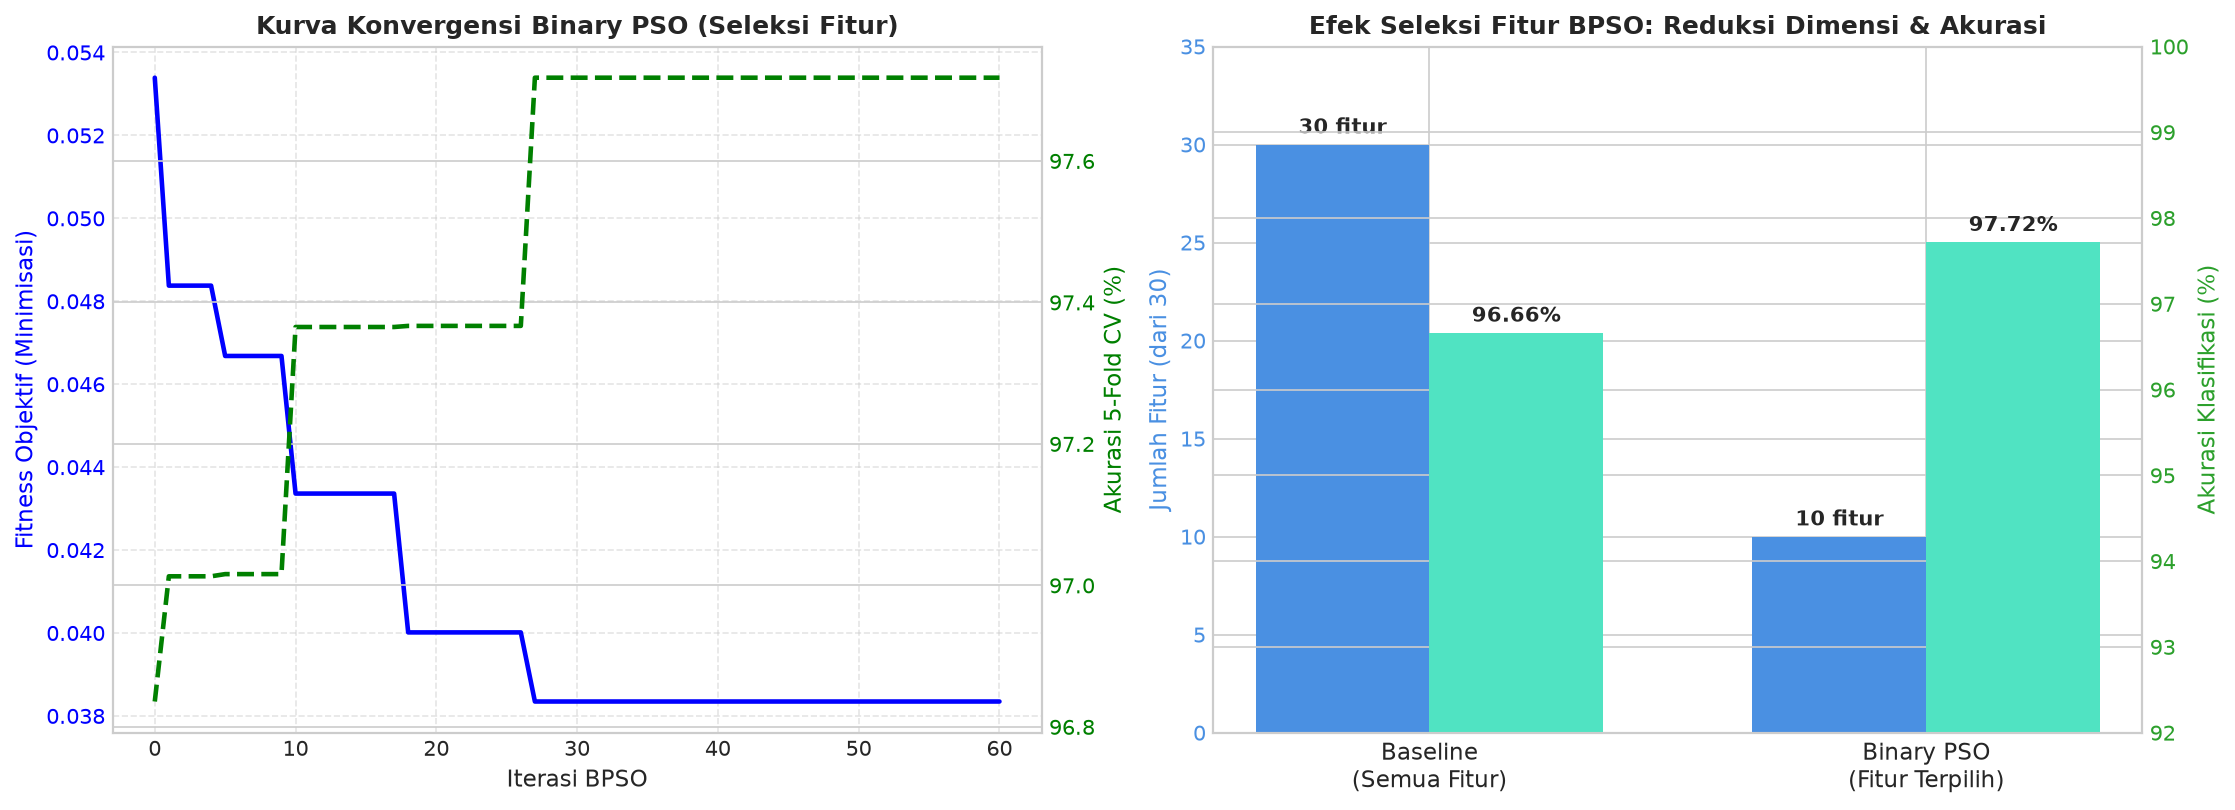

In [9]:
# Visualisasi Performa Binary PSO
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# 1. Kurva Konvergensi BPSO
iters = np.arange(len(bpso_res['history_fitness']))
ax1 = axes[0]
ax1.plot(iters, bpso_res['history_fitness'], 'b-', linewidth=2.2, label='Fitness Objektif')
ax1.set_xlabel("Iterasi BPSO", fontsize=11)
ax1.set_ylabel("Fitness Objektif (Minimisasi)", color='b', fontsize=11)
ax1.tick_params(axis='y', labelcolor='b')
ax1.grid(True, linestyle='--', alpha=0.5)

ax1_t = ax1.twinx()
ax1_t.plot(iters, bpso_res['history_acc'] * 100, 'g--', linewidth=2.2, label='Akurasi CV (%)')
ax1_t.set_ylabel("Akurasi 5-Fold CV (%)", color='g', fontsize=11)
ax1_t.tick_params(axis='y', labelcolor='g')
ax1.set_title("Kurva Konvergensi Binary PSO (Seleksi Fitur)", fontweight='bold', fontsize=12)

# 2. Diagram Batang Perbandingan Reduksi Fitur & Akurasi
ax2 = axes[1]
categories = ['Baseline\n(Semua Fitur)', 'Binary PSO\n(Fitur Terpilih)']
n_feats = [len(feat_names), len(selected_indices)]
accs = [base_acc * 100, bpso_res['gbest_acc'] * 100]

x = np.arange(len(categories))
w = 0.35

bar1 = ax2.bar(x - w/2, n_feats, w, label='Jumlah Fitur', color='#4a90e2')
ax2.set_ylabel('Jumlah Fitur (dari 30)', color='#4a90e2', fontsize=11)
ax2.tick_params(axis='y', labelcolor='#4a90e2')
ax2.set_xticks(x)
ax2.set_xticklabels(categories, fontsize=11)
ax2.set_ylim(0, 35)

ax2_t = ax2.twinx()
bar2 = ax2_t.bar(x + w/2, accs, w, label='Akurasi (%)', color='#50e3c2')
ax2_t.set_ylabel('Akurasi Klasifikasi (%)', color='#2ca02c', fontsize=11)
ax2_t.tick_params(axis='y', labelcolor='#2ca02c')
ax2_t.set_ylim(92, 100)

for b in bar1:
    h = b.get_height()
    ax2.annotate(f'{int(h)} fitur', xy=(b.get_x() + b.get_width() / 2, h),
                 xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontweight='bold')
for b in bar2:
    h = b.get_height()
    ax2_t.annotate(f'{h:.2f}%', xy=(b.get_x() + b.get_width() / 2, h),
                   xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontweight='bold')

ax2.set_title("Efek Seleksi Fitur BPSO: Reduksi Dimensi & Akurasi", fontweight='bold', fontsize=12)
plt.tight_layout()
plt.show()

## 8. Kesimpulan

Berdasarkan keseluruhan implementasi, eksperimen numerik 30 run pada fungsi benchmark kontinu ($D=10$), dan pengujian seleksi fitur biner pada dataset riil UCI, dapat ditarik beberapa kesimpulan utama:

1. **Efektivitas Varian Inersia dan Konstriksi:**
   - **$w$ Tetap ($w = 0.7$):** Memberikan kinerja eksploitasi terbaik pada fungsi unimodal Sphere ($1.247 \times 10^{-11}$) dan memiliki performa paling unggul pada fungsi multimodal Rastrigin ($8.392$). Hal ini disebabkan inersia konstan mempertahankan fleksibilitas partikel untuk terus melompati cekungan lokal tanpa membeku prematur.
   - **Constriction Factor ($\chi = 0.7298$):** Sangat stabil dan menjamin konvergensi redaman secara teoritis. Menghasilkan pencapaian sangat baik pada Sphere ($6.831 \times 10^{-10}$), namun cenderung lebih cepat terperangkap dalam local minima pada Rastrigin saat partikel kehilangan energi kinetik.
   - **$w$ Menurun Linier ($0.9 \to 0.4$):** Memiliki fase eksplorasi awal yang agresif, namun penurunan bobot hingga $0.4$ membatasi kemampuan eksploitasi sub-mikro pada Sphere ($5.924 \times 10^{-6}$) dan membekukan partikel di jebakan lokal Rastrigin ($10.058$).

2. **Peran Kunci Velocity Clamping & Boundary Handling:**
   - Pembatasan kecepatan $v_{\max} = 0.2 \times (x_{\max} - x_{\min})$ terbukti mutlak diperlukan untuk mencegah fenomena ledakan kawanan partikel (*swarm explosion*), khususnya pada lanskap multimodal terjal seperti Rastrigin.
   - Penanganan batas dengan me-reset kecepatan $v = 0$ secara efektif mengembalikan partikel ke dalam domain pencarian tanpa fenomena pemantulan osilasi tak terkendali.

3. **Keberhasilan Binary PSO (BPSO) pada Dataset UCI:**
   - Algoritma BPSO yang dibangun dari nol dengan transfer function Sigmoid berhasil mereduksi dimensi fitur dataset UCI Breast Cancer Wisconsin sebesar **66.7%** (dari 30 fitur menjadi hanya **10 fitur terpilih**).
   - Akurasi klasifikasi k-NN 5-fold cross validation justru meningkat dari **96.66%** menjadi **97.72%** (+1.06%). Hal ini membuktikan bahwa BPSO efektif mengeliminasi fitur-fitur redundan dan *noisy*, menyisakan subset prediktor paling diskriminatif.